In [1]:

from matplotlib import pyplot as plt
import pandas as pd
import numpy as np
import statsmodels.tsa.api as smt

In [2]:
# аналогичным образом загружаем данные о пассажирах
df = pd.read_csv('data/chai_stall_diaries.csv')
# неподходящий формат данных приводим к тому, с которым Pandas может работать

df.set_index('date').sort_index()

,day_of_week,month,is_weekend,temp_c,rain_mm,cricket_match_day,exam_season,special_day,staff_on_duty,chai_price_pkr,chai_cups_sold,coffee_cups_sold,samosas_sold,busiest_hour,customer_rating,daily_revenue_pkr
date,,,,,,,,,,,,,,,,
2024-10-01,Tuesday,October,0,25.3,0.0,No,No,NaN,1,65,55,14,25,6 PM,4.0,5885
2024-10-02,Wednesday,October,0,26.1,0.0,No,No,NaN,1,64,35,14,17,4 PM,4.5,4281
2024-10-03,Thursday,October,0,24.7,0.0,No,No,NaN,1,62,51,13,32,6 PM,4.5,5396
2024-10-04,Friday,October,1,21.9,0.0,No,No,NaN,3,64,71,23,36,6 PM,NaN,8041
2024-10-05,Saturday,October,1,NaN,0.0,No,No,NaN,3,60,78,25,48,6 PM,4.0,8631
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-26,Saturday,September,1,25.8,0.0,No,No,NaN,2,79,53,27,22,4 PM,4.0,8189
2026-09-27,Sunday,September,1,24.8,0.0,No,No,NaN,2,82,59,21,36,6 PM,4.5,8449
2026-09-28,Monday,September,0,29.8,0.0,No,No,NaN,1,82,36,24,28,4 PM,3.0,6776


In [3]:
df.head

<bound method NDFrame.head of            date day_of_week      month  is_weekend  temp_c  rain_mm  \
0    2024-10-01     Tuesday    October           0    25.3      0.0   
1    2024-10-02   Wednesday    October           0    26.1      0.0   
2    2024-10-03    Thursday    October           0    24.7      0.0   
3    2024-10-04      Friday    October           1    21.9      0.0   
4    2024-10-05    Saturday    October           1     NaN      0.0   
..          ...         ...        ...         ...     ...      ...   
728  2026-09-26    Saturday  September           1    25.8      0.0   
729  2026-09-27      Sunday  September           1    24.8      0.0   
730  2026-09-28      Monday  September           0    29.8      0.0   
731  2026-09-29     Tuesday  September           0    23.4      0.0   
732  2026-09-30   Wednesday  September           0    26.7      0.0   

    cricket_match_day exam_season special_day  staff_on_duty  chai_price_pkr  \
0                  No          No    

### Скользящее среднее

In [4]:
df['MA_window_3'] = df['chai_cups_sold'].rolling(window=3).mean()
df

,date,day_of_week,month,is_weekend,temp_c,rain_mm,cricket_match_day,exam_season,special_day,staff_on_duty,chai_price_pkr,chai_cups_sold,coffee_cups_sold,samosas_sold,busiest_hour,customer_rating,daily_revenue_pkr,MA_window_3
0,2024-10-01,Tuesday,October,0,25.3,0.0,No,No,NaN,1,65,55,14,25,6 PM,4.0,5885,NaN
1,2024-10-02,Wednesday,October,0,26.1,0.0,No,No,NaN,1,64,35,14,17,4 PM,4.5,4281,NaN
2,2024-10-03,Thursday,October,0,24.7,0.0,No,No,NaN,1,62,51,13,32,6 PM,4.5,5396,47.000000
3,2024-10-04,Friday,October,1,21.9,0.0,No,No,NaN,3,64,71,23,36,6 PM,NaN,8041,52.333333
4,2024-10-05,Saturday,October,1,NaN,0.0,No,No,NaN,3,60,78,25,48,6 PM,4.0,8631,66.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
728,2026-09-26,Saturday,September,1,25.8,0.0,No,No,NaN,2,79,53,27,22,4 PM,4.0,8189,71.000000
729,2026-09-27,Sunday,September,1,24.8,0.0,No,No,NaN,2,82,59,21,36,6 PM,4.5,8449,65.333333
730,2026-09-28,Monday,September,0,29.8,0.0,No,No,NaN,1,82,36,24,28,4 PM,3.0,6776,49.333333
731,2026-09-29,Tuesday,September,0,23.4,0.0,No,No,NaN,1,79,42,13,24,4 PM,4.0,5667,45.666667


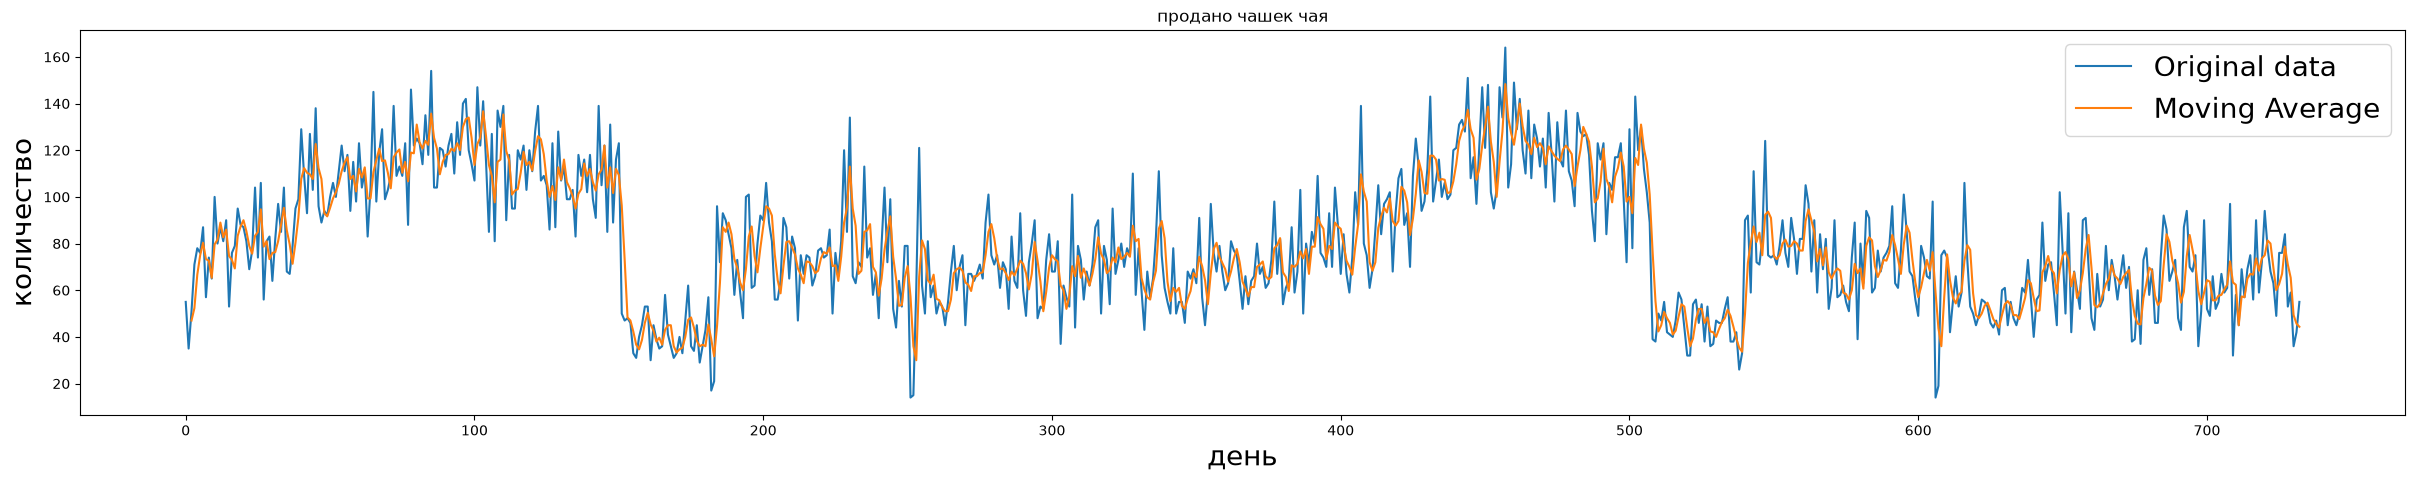

In [5]:
fig = plt.figure(figsize=(30, 5))
plt.plot(df['chai_cups_sold'], label='Original data')
plt.plot(df['MA_window_3'], label='Moving Average')
plt.legend(fontsize="20")
plt.title('продано чашек чая')
plt.ylabel('количество', fontsize="20")
plt.xlabel('день', fontsize="20")
plt.show()

Можно поиграться с размерностью окна

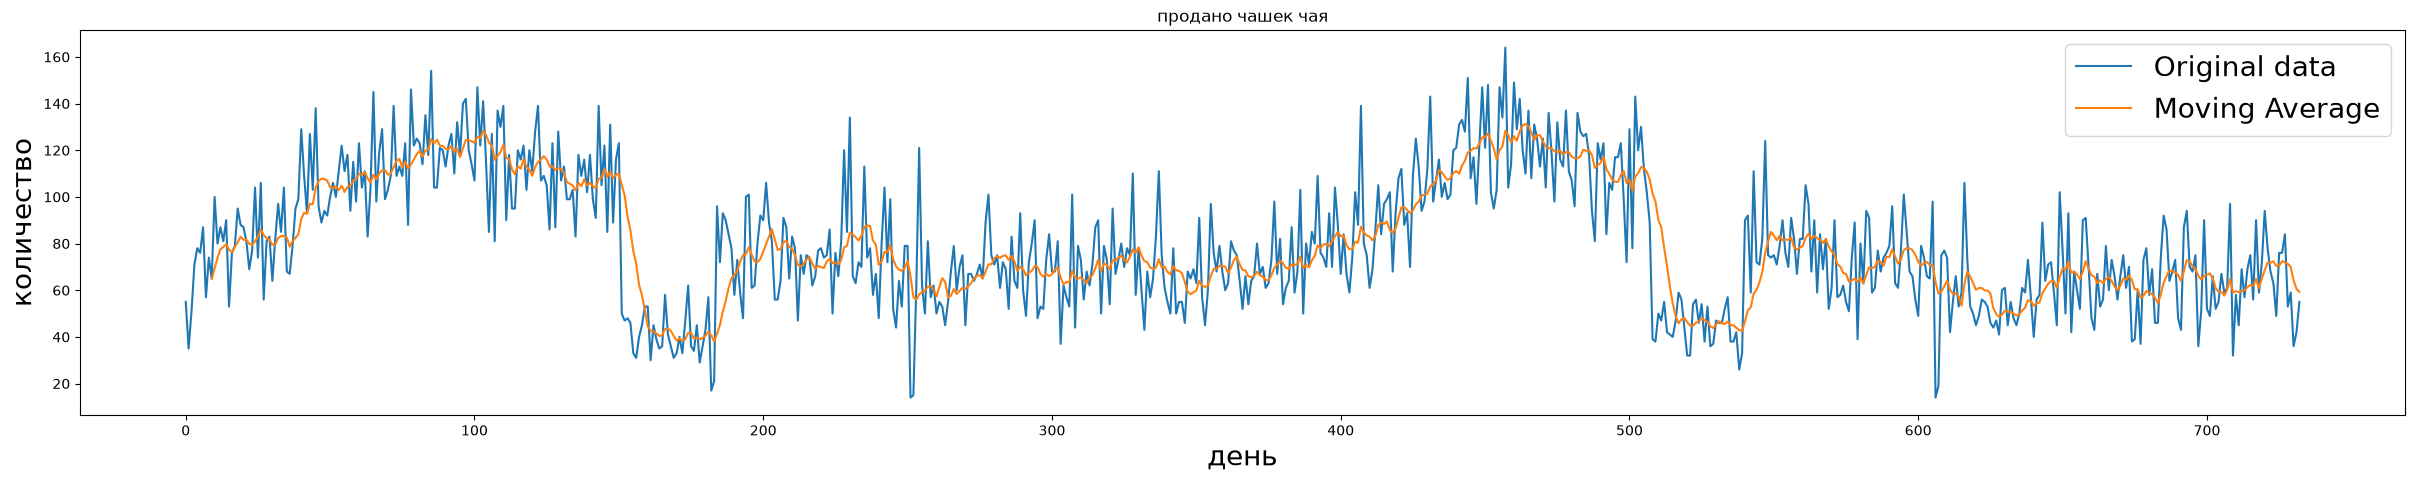

In [6]:
df['MA_window_6'] = df['chai_cups_sold'].rolling(window=10).mean()
fig = plt.figure(figsize=(30, 5))
plt.plot(df['chai_cups_sold'], label='Original data')
plt.plot(df['MA_window_6'], label='Moving Average')
plt.legend(fontsize="20")
plt.title('продано чашек чая')
plt.ylabel('количество', fontsize="20")
plt.xlabel('день', fontsize="20")
plt.show()


Давайте напишем функцию, которая поможет нам понять тенденцию и движения временного ряда. Мы хотим видеть на графике некоторую скользящую статистику, такую как:

M скользящее среднее: невзвешенное среднее предыдущих n данных (также называемое скользящим средним).

Полосы Боллинджера: верхняя полоса в k раз на n -периодное стандартное отклонение выше скользящей средней и нижняя полоса в k раз на стандартное отклонение N ниже.

In [7]:
'''
Отрисовка скользящего среднего по медиане для ts с 95% доверительным интервалом для стандартного отклонения.
:parameter
  :param ts: датасет
  :param window: кол-во семплов в окне - для скользящих средних
  :param plot_ma: bool - whether plot moving average
  :param plot_intervals: bool - whether plot upper and lower bounds
'''
def plot_ts(ts, plot_ma=True, plot_intervals=True, window=100,
            figsize=(15,5)):
    rolling_mean = ts.rolling(window=window).mean()
    rolling_std = ts.rolling(window=window).std()
    plt.figure(figsize=figsize)
    plt.title(ts.name)
    plt.plot(ts[window:], label='Реальные значения', color="black")
    if plot_ma:
        plt.plot(rolling_mean, 'g', label='MA'+str(window),
                 color="red")
    if plot_intervals:
        lower_bound = rolling_mean - (1.96 * rolling_std)
        upper_bound = rolling_mean + (1.96 * rolling_std)
    plt.fill_between(x=ts.index, y1=lower_bound, y2=upper_bound,
                     color='lightskyblue', alpha=0.6)
    plt.legend(loc='best')
    plt.grid(True)
    plt.show()

C:\Users\krapa\AppData\Local\Temp\ipykernel_24884\2165458639.py:17: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "g" (-> color=(0.0, 0.5, 0.0, 1)). The keyword argument will take precedence.
  plt.plot(rolling_mean, 'g', label='MA'+str(window),


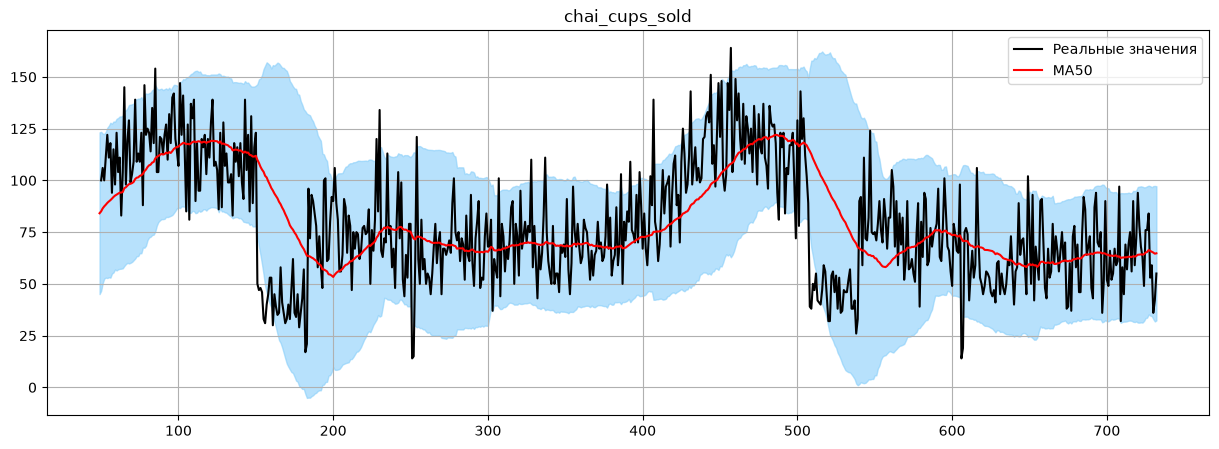

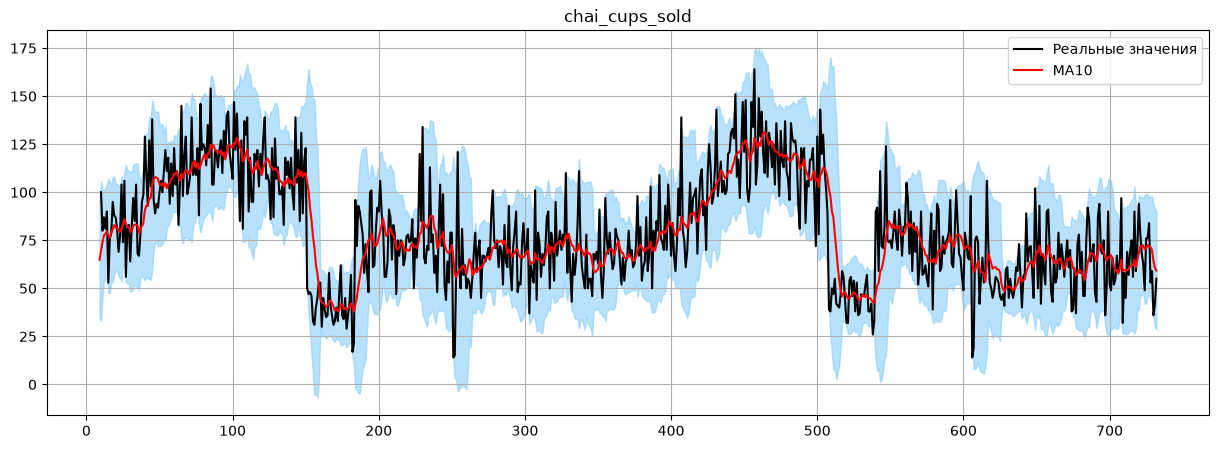

In [8]:
plot_ts(df["chai_cups_sold"], window=50)
plot_ts(df["chai_cups_sold"], window=10)

### ARMA

In [9]:
from statsmodels.tsa.arima.model import ARIMA

## Предсказание ряда на основе предыдущих значений

### ARIMA  

Модель авторегрессии скользящего среднего и систематический подход к её построению предназначена для анализа стационарных временных рядов на основе оценки линейной зависимости прогнозируемых значений от исторических.

Для использования модели временной ряд должен быть стационарным, т.е. его среднее и дисперсия должны быть постоянны.

Модель Бокса-Дженкинса предполагает, что временной ряд содержит три составляющие: авторегресионную, интегрированную и скользящее среднее, которые в модели обозначены $p$, $d$ и $q$ соответственно:

* Величина $p$ называется порядком авторегрессии. Она позволяет ответить на вопрос, будет ли очередной элемент ряда близок к значению $X$, если к нему были близки $p$ предыдущих значений.
* Величину $d$ называют порядком интегрирования. Она показывает, насколько элемент ряда близок по значению к $d$ предыдущим значениям, если разность между ними минимальна.

* Параметр $q$— порядок скользящего среднего. Позволяет установить погрешность модели как линейную комбинацию наблюдавшихся ранее значений ошибок.

Авторегрессия — это составляющая модели временного ряда, в которой его прогнозируемое значение может быть выражено в виде линейной комбинации исторических значений этого же ряда и случайной ошибки.

Обычно модель упоминается, как ARIMA$(p,d,q)$, где $p$, $d$ и $q$ — целые неотрицательные числа, характеризующие порядок для частей модели (соответственно авторегрессионной, интегрированной и скользящего среднего).

Для временного ряда $X(t)$ модель может быть записана в виде:

$$(\delta^dX_t)=\sum^p_{t=1}a_t(\delta^dX_{t-1}) + \epsilon_t + \sum^q_{j=1}b_j(\delta^d\epsilon_{t-j})$$

где

* $\delta^d$ — оператор разности порядка $d$ (последовательное взятие $d$ раз разностей первого порядка — сначала от самого ряда, затем от полученных разностей первого порядка, затем от второго порядка и т. д.);
* $a_t$— коэффициенты авторегрессионной части модели, $\epsilon_t$— значения ошибки (полагаются независимыми одинаково распределёнными случайными величинами из нормального распределения с нулевым средним);
* $b_j$ — коэффициенты скользящего среднего.

Модель Бокса-Дженкинса широко применяются при прогнозировании временных рядов. Основная задача при этом заключается в оценке параметров модели. Методология построения ARIMA-модели исследуемого временного ряда включает следующие основные этапы:

* построение пробной модели;
* оценивание параметров модели и проверка адекватности модели;
* использование модели для прогнозирования.

Чтобы построить модель ARMA, мы можем использовать функцию ARIMA (которая будет
объяснена в следующем разделе) в statsmodels.tsa.arima.model и указать
гиперпараметр — order(p, d, q). Когда d = 0, он работает как модель ARMA.

In [10]:
arma_model = ARIMA(df['chai_cups_sold'], order=(5,0,3))
arma_model_fit = arma_model.fit()

C:\Users\krapa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\krapa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [11]:
print(arma_model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:         chai_cups_sold   No. Observations:                  733
Model:                 ARIMA(5, 0, 3)   Log Likelihood               -3155.284
Date:                Sat, 21 Nov 2026   AIC                           6330.568
Time:                        11:31:10   BIC                           6376.540
Sample:                             0   HQIC                          6348.301
                                - 733                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         79.7026      7.931     10.049      0.000      64.158      95.247
ar.L1          0.6934      0.181      3.830      0.000       0.339       1.048
ar.L2          0.5824      0.167      3.488      0.0

In [12]:
X = df['chai_cups_sold'].values
size = int(len(X) * 0.66)
train, test = X[0:size], X[size:len(X)]
history = [x for x in train]
arma_predictions = list()
# walk-forward validation
for t in range(len(test)):
    model = ARIMA(history, order=(5,0,3))
    model_fit = model.fit()
    output = model_fit.forecast()
    yhat = output[0]
    arma_predictions.append(yhat)
    obs = test[t]
    history.append(obs)

C:\Users\krapa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\krapa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\krapa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\krapa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_para

In [13]:
print(len(train))
print(len(test))
print(len(arma_predictions))

483
250
250


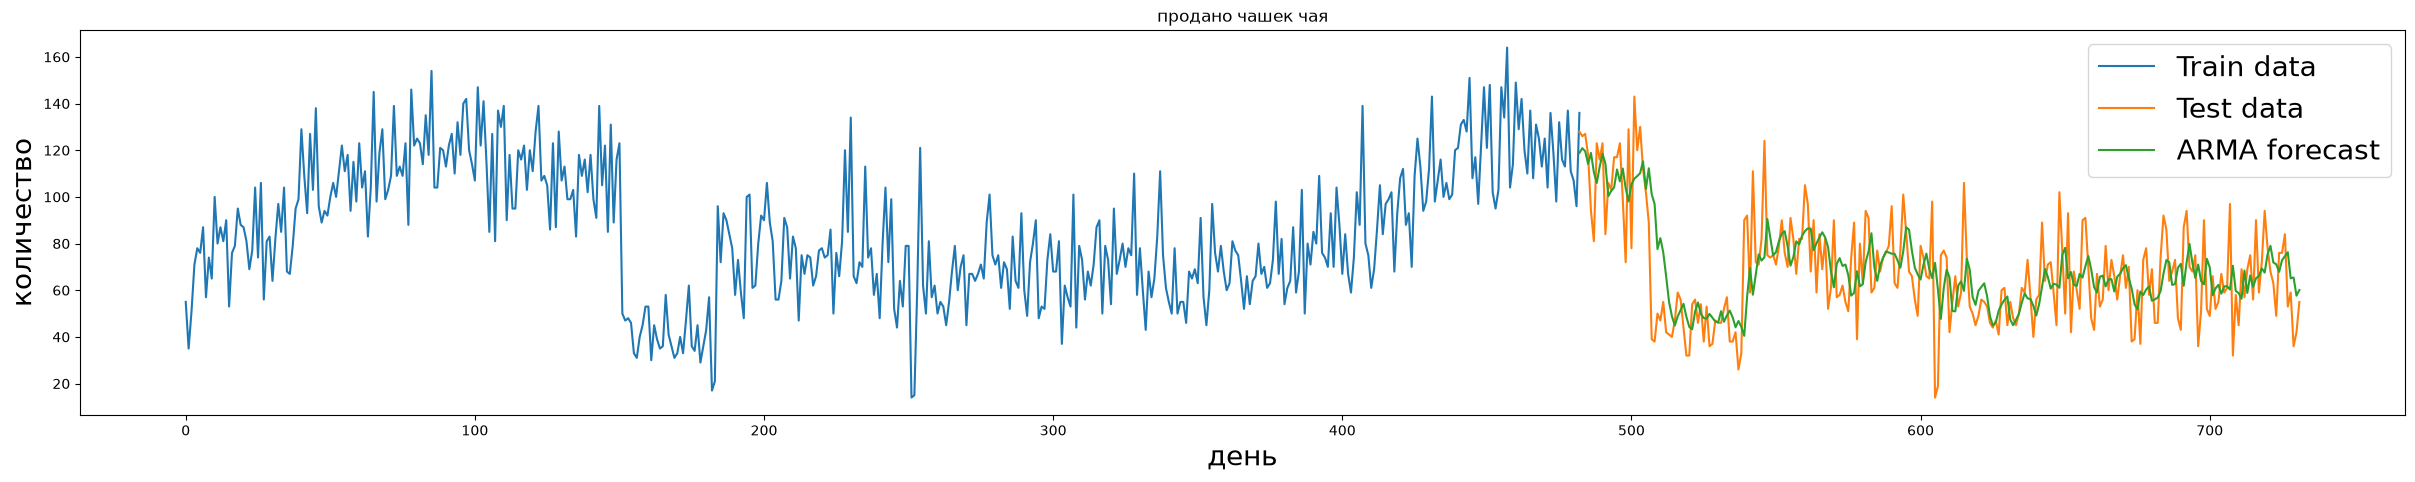

In [14]:
fig = plt.figure(figsize=(30, 5))
dur = len(arma_predictions)

plt.plot([i for i in range(0, size)], train, label='Train data')
plt.plot([i for i in range(size - 1, size - 1 + dur)], test[:dur], label='Test data')
plt.plot([i for i in range(size - 1, size - 1 + dur)], arma_predictions, label='ARMA forecast')
plt.legend(fontsize="20")
plt.title('продано чашек чая')
plt.ylabel('количество', fontsize="20")
plt.xlabel('день', fontsize="20")
plt.show()

### ARIMA

In [15]:
arima_model = ARIMA(df['chai_cups_sold'], order=(10,2,10))
arima_model_fit = arima_model.fit()

C:\Users\krapa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\krapa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\krapa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [16]:
print(arima_model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:         chai_cups_sold   No. Observations:                  733
Model:               ARIMA(10, 2, 10)   Log Likelihood               -3126.601
Date:                Sat, 21 Nov 2026   AIC                           6295.202
Time:                        11:34:25   BIC                           6391.685
Sample:                             0   HQIC                          6332.424
                                - 733                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -2.3429      0.151    -15.475      0.000      -2.640      -2.046
ar.L2         -3.0888      0.279    -11.076      0.000      -3.635      -2.542
ar.L3         -3.0259      0.415     -7.289      0.0

Полезным может быть получение линейного графика остаточных ошибок, что позволяет предположить, что некоторая информация о тенденциях все еще может быть не учтена моделью.

<Axes: >

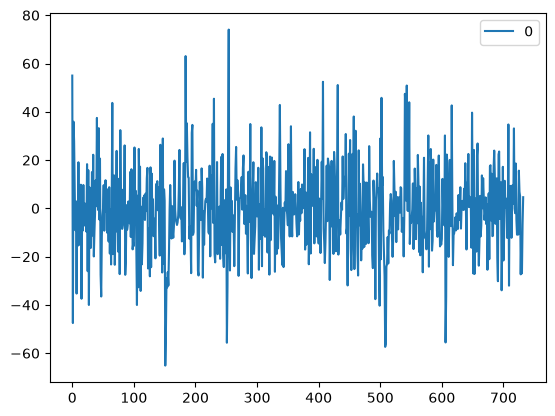

In [17]:
arima_residuals = pd.DataFrame(arima_model_fit.resid)
arima_residuals.plot()

Осуществляем предсказание

In [18]:
# forecast предсказывает только следующее значение
output = arima_model_fit.forecast()

In [19]:
X = df['chai_cups_sold'].values
size = int(len(X) * 0.66)
train, test = X[0:size], X[size:len(X)]
history = [x for x in train]
arima_predictions = list()
# walk-forward validation
for t in range(len(test)):
    arima_model = ARIMA(history, order=(10,2,5))
    arima_model_fit = arima_model.fit()
    output = arima_model_fit.forecast()
    yhat = output[0]
    arima_predictions.append(yhat)
    obs = test[t]
    history.append(obs)

C:\Users\krapa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\krapa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\krapa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\krapa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.st

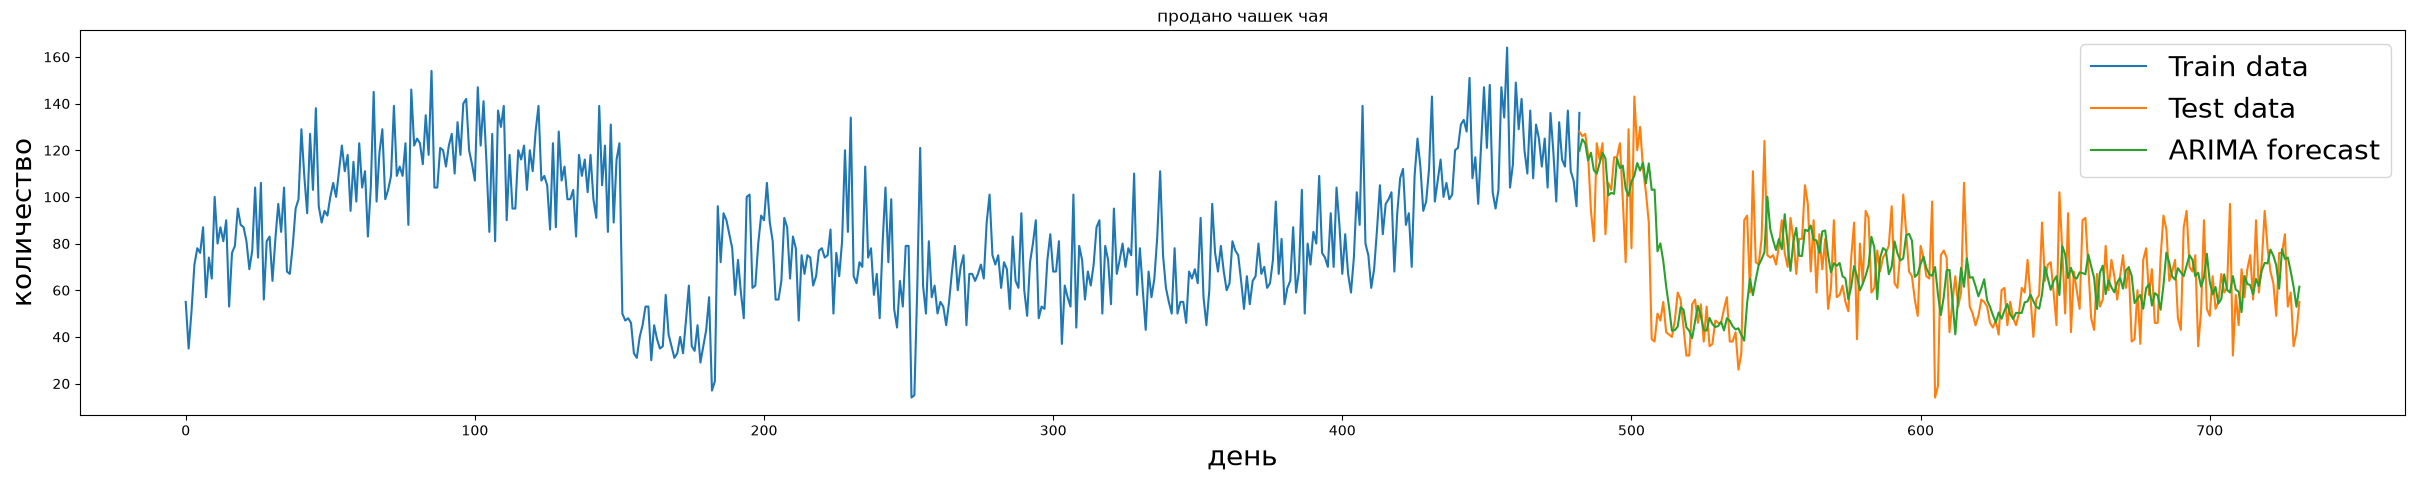

In [20]:
fig = plt.figure(figsize=(30, 5))
plt.plot([i for i in range(0, size)], train, label='Train data')
plt.plot([i for i in range(size - 1, len(X) - 1)], test, label='Test data')
plt.plot([i for i in range(size - 1, len(X) - 1)], arima_predictions, label='ARIMA forecast')
plt.legend(fontsize="20")
plt.title('продано чашек чая')
plt.ylabel('количество', fontsize="20")
plt.xlabel('день', fontsize="20")
plt.show()

Сравним значения ARMA и ARIMA

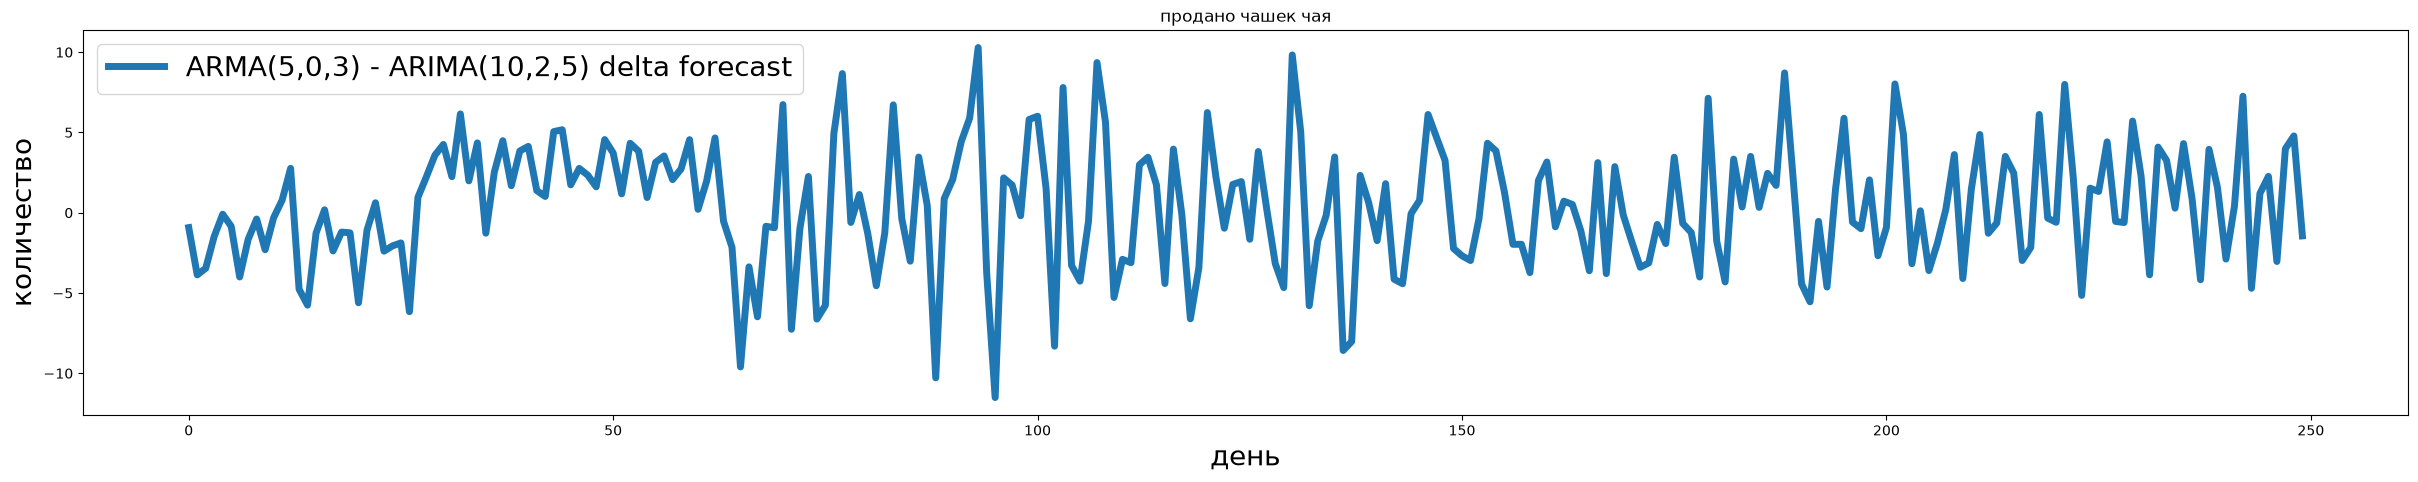

In [21]:
fig = plt.figure(figsize=(30, 5))

delta = []

for i in range(len(arima_predictions)):
    delta.append(arma_predictions[i] - arima_predictions[i])

plt.plot(delta, label='ARMA(5,0,3) - ARIMA(10,2,5) delta forecast', linewidth=5)
plt.legend(fontsize="20")
plt.title('продано чашек чая')
plt.ylabel('количество', fontsize="20")
plt.xlabel('день', fontsize="20")
plt.show()

### Работа с пропусками данных

* Заполнение средним и медианой​
* Заполнение предыдущим и последующим значениями​
* Заполнение скользящим средним и медианой​
* Заполнение с помощью предсказания моделей машинного обучения​
* Интерполяция

Заполнение средним и медианой

<Axes: >

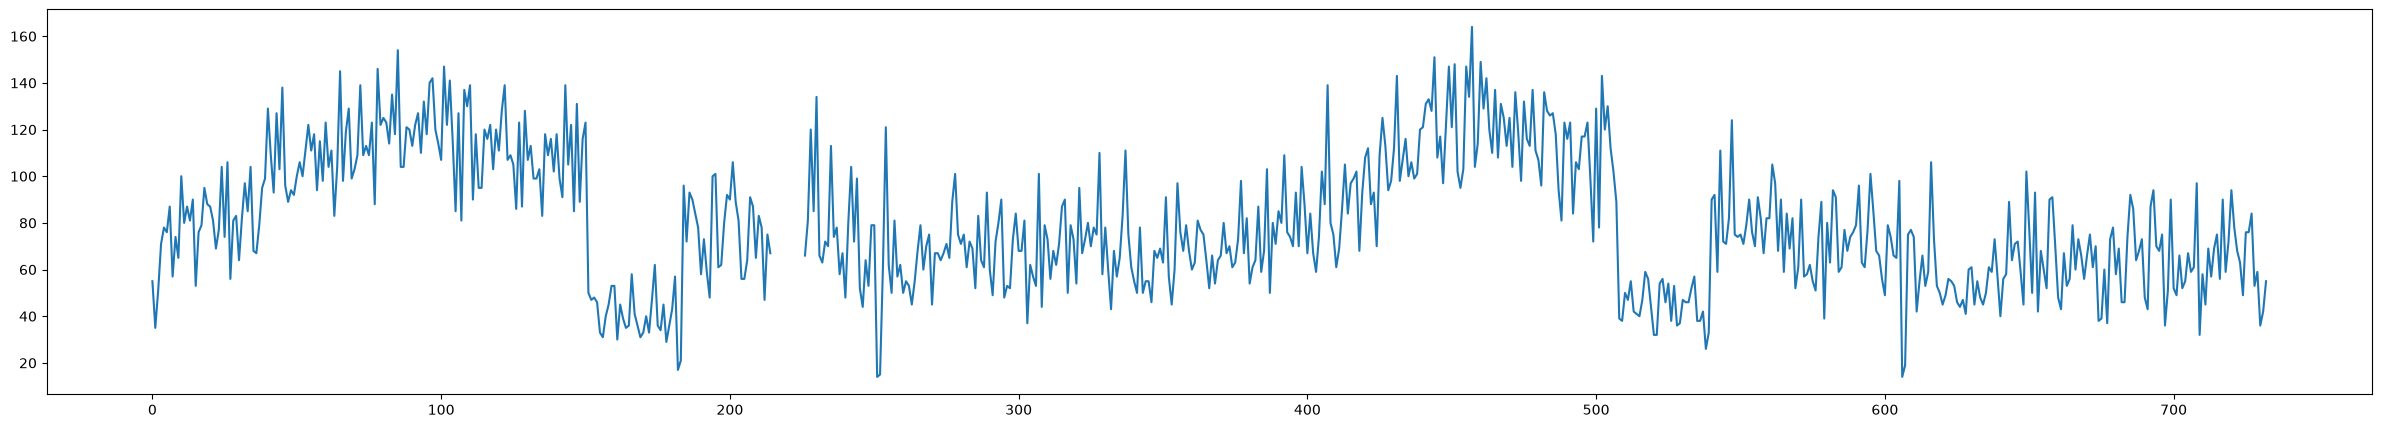

In [22]:
o_df = df.copy()

o_df.loc[215:225, 'chai_cups_sold'] = np.nan

o_df['chai_cups_sold'].plot(figsize=(30, 5))

<Axes: title={'center': 'среднее из предыдущего и последующего'}>

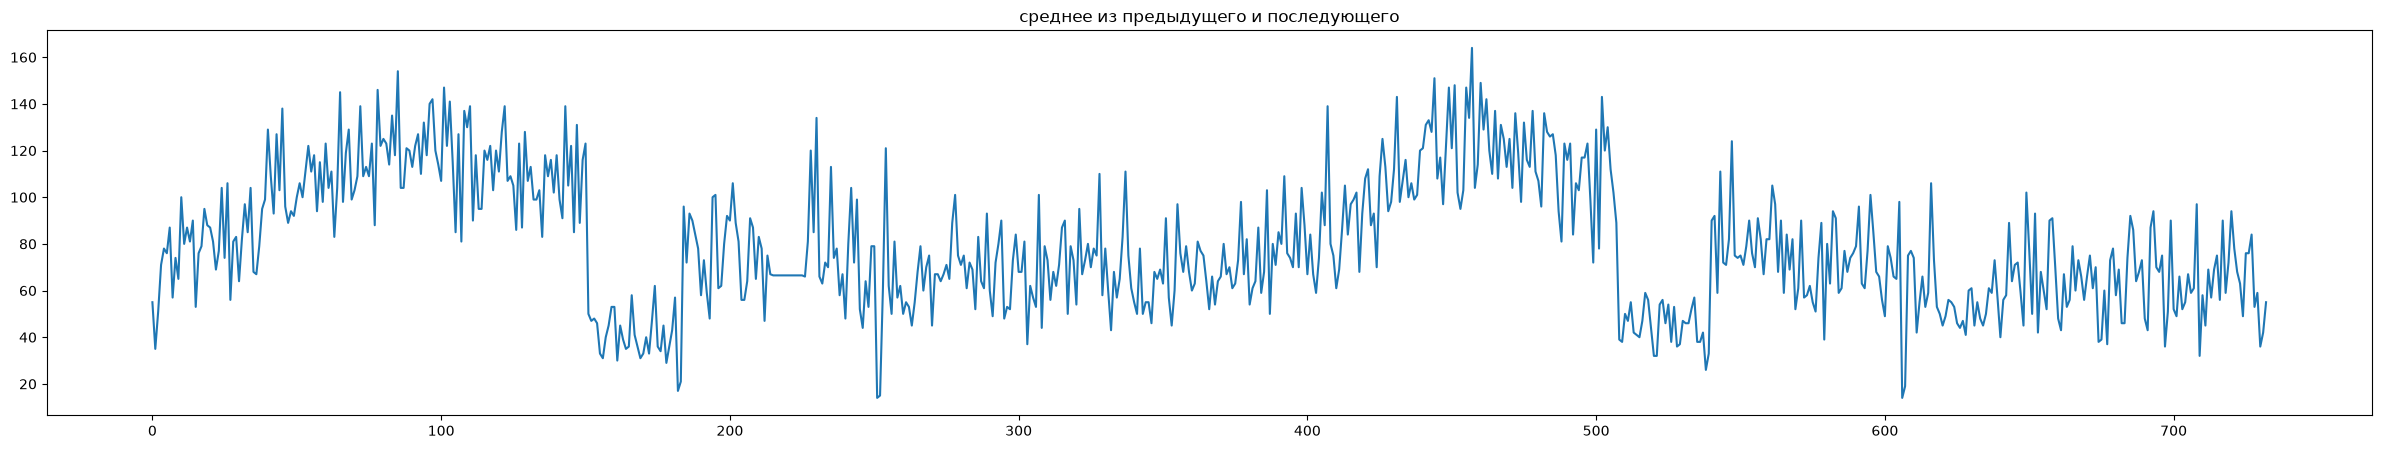

In [23]:
new_value = (o_df['chai_cups_sold'][226] + o_df['chai_cups_sold'][214])/2

o_df.loc[215:225, 'chai_cups_sold'] = new_value

o_df['chai_cups_sold'].plot(title="среднее из предыдущего и последующего", figsize=(30, 5))

Заполнение предыдущим и последующим значениями​

<Axes: title={'center': 'Последующее значение'}>

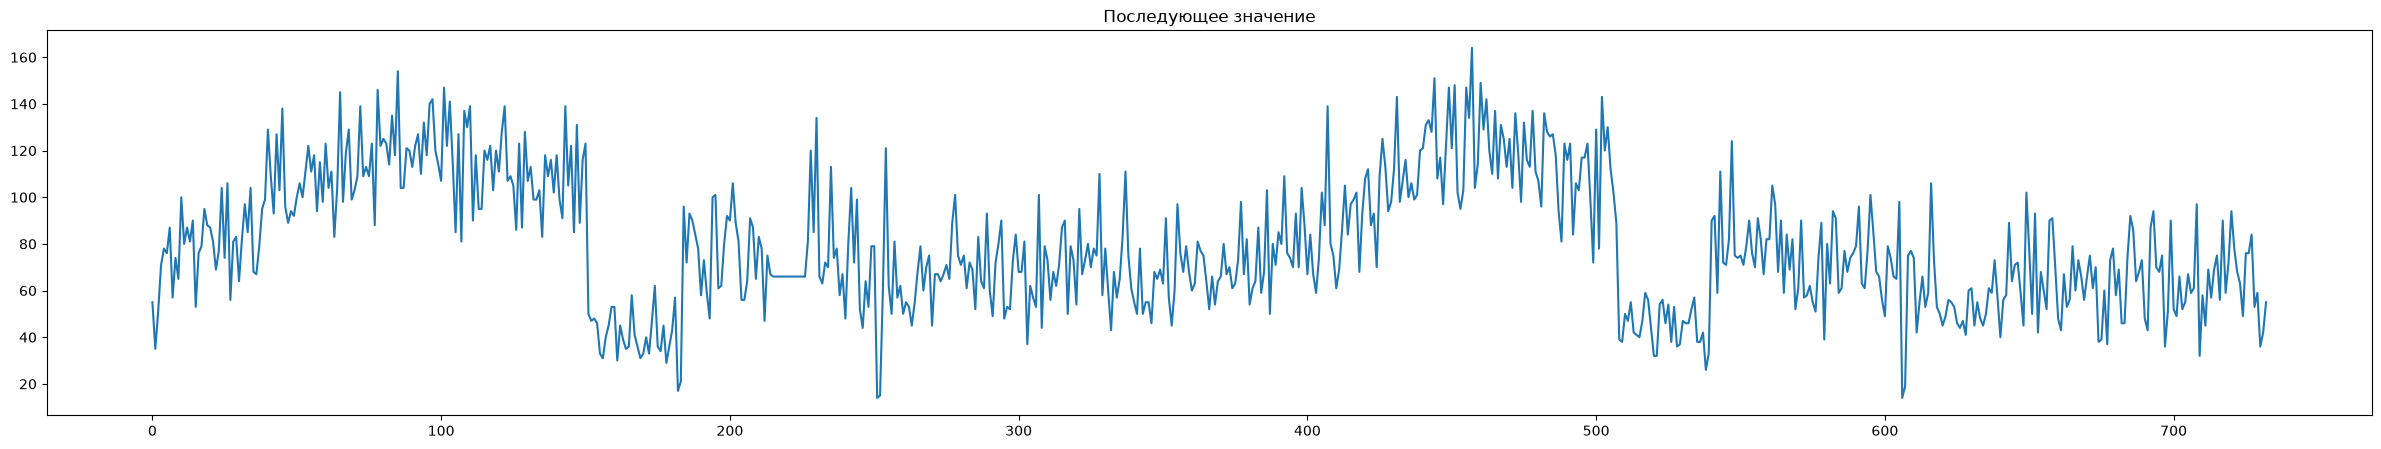

In [24]:
new_value = o_df['chai_cups_sold'][226]

o_df.loc[215:225, 'chai_cups_sold'] = new_value

o_df['chai_cups_sold'].plot(title='Последующее значение', figsize=(30, 5))

<Axes: title={'center': 'Предыдущее значение'}>

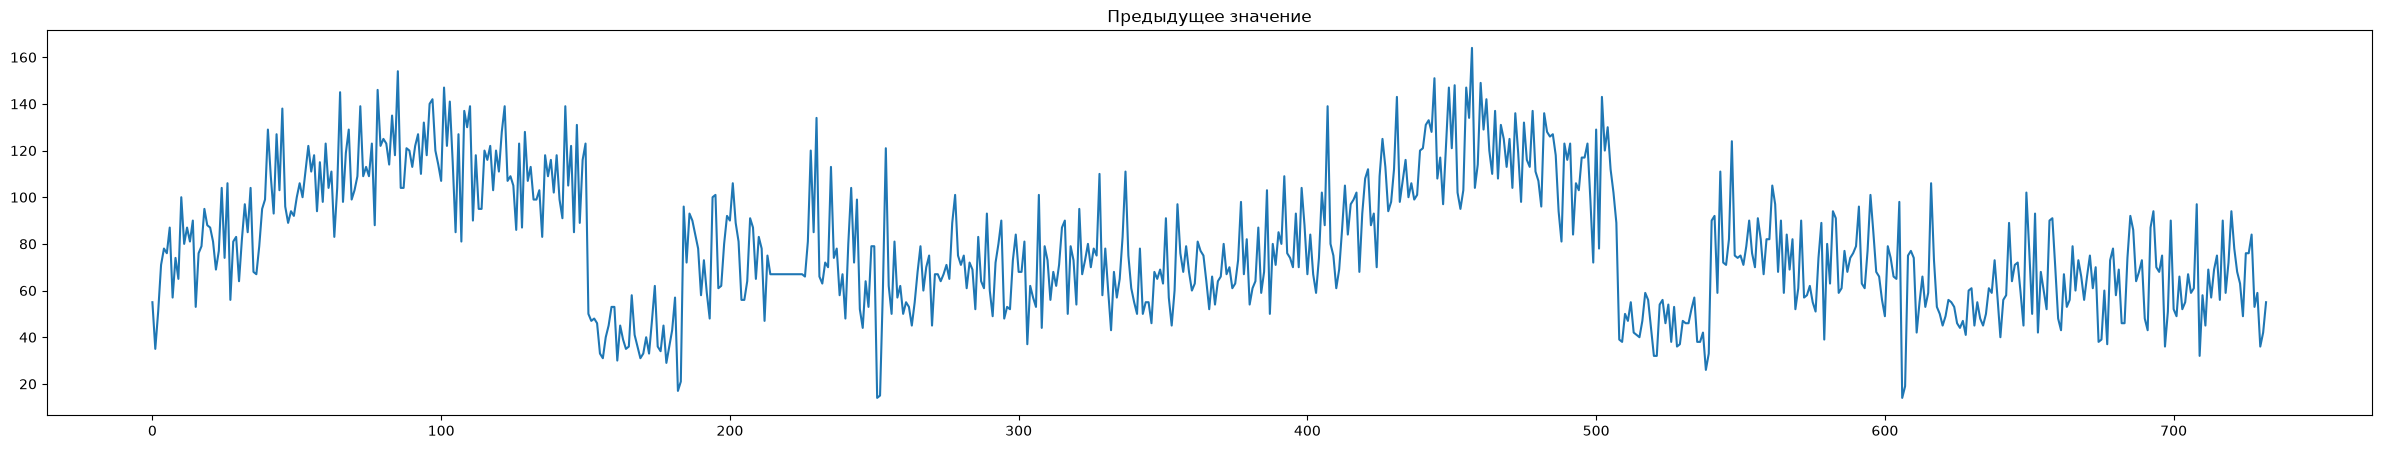

In [25]:
new_value = o_df['chai_cups_sold'][214]

o_df.loc[215:225, 'chai_cups_sold'] = new_value

o_df['chai_cups_sold'].plot(title='Предыдущее значение', figsize=(30, 5))

Заполнение скользящим средним и медианой​

<Axes: title={'center': 'медиана'}>

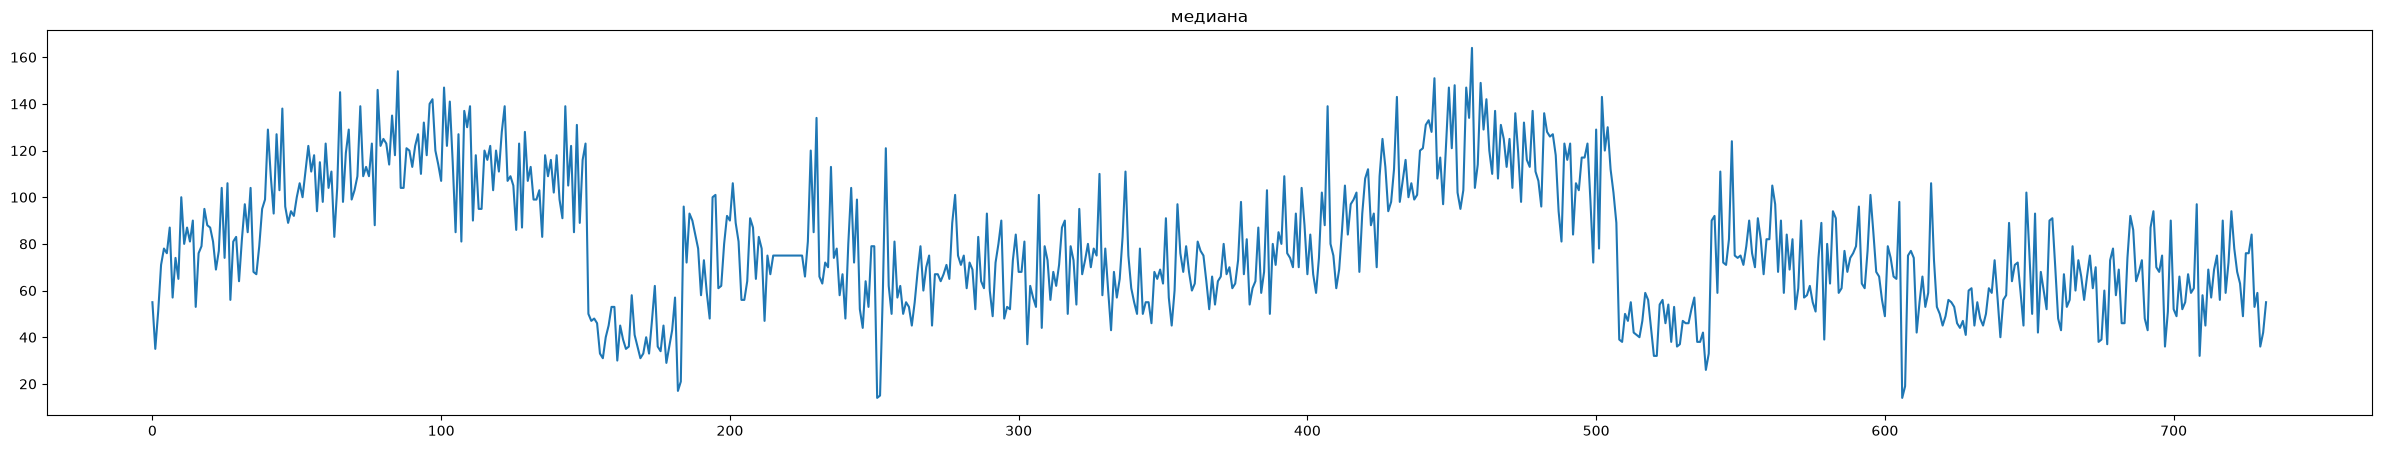

In [26]:
new_value = o_df['chai_cups_sold'].median()

o_df.loc[215:225, 'chai_cups_sold'] = new_value

o_df['chai_cups_sold'].plot(title='медиана', figsize=(30, 5))

<Axes: title={'center': 'среднее'}>

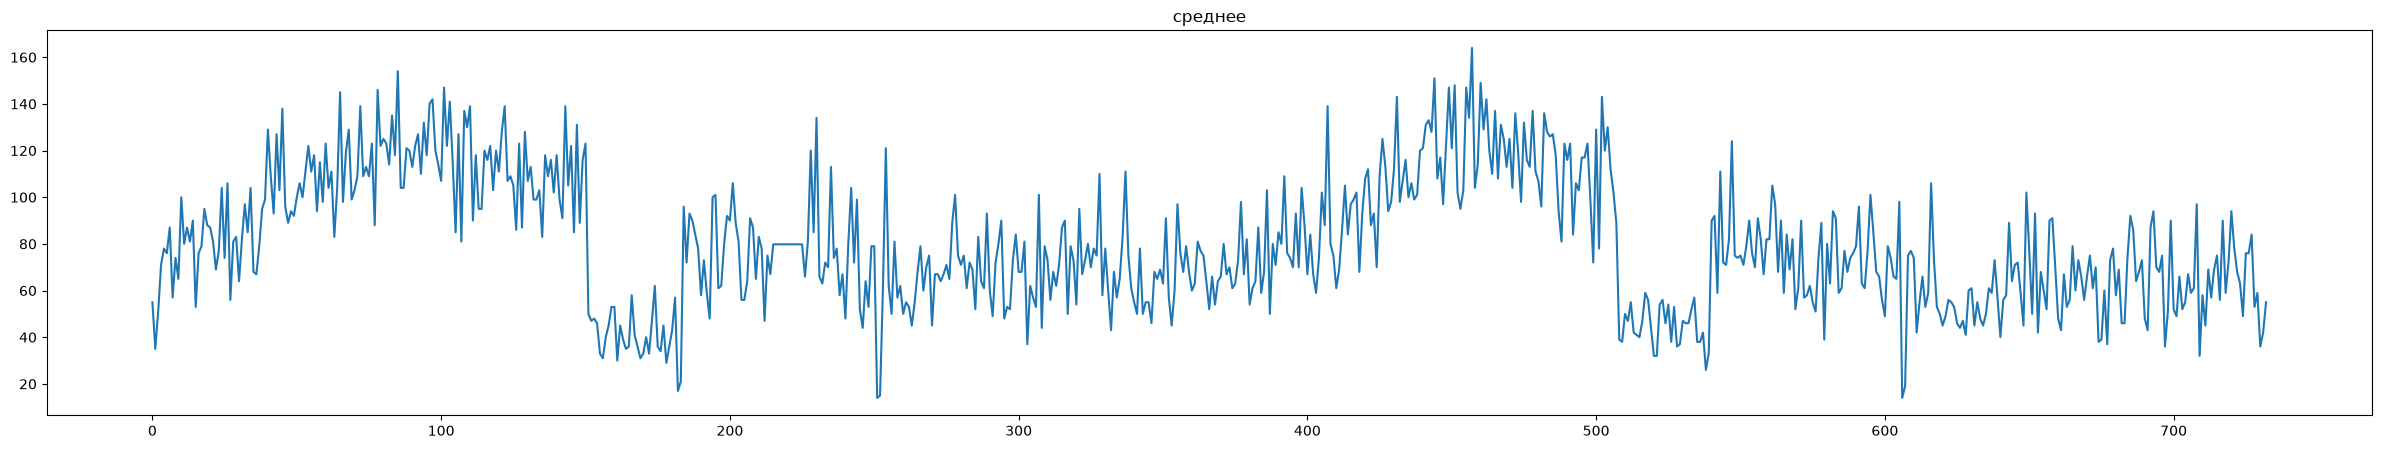

In [27]:
new_value = o_df['chai_cups_sold'].mean()

o_df.loc[215:225, 'chai_cups_sold'] = new_value

o_df['chai_cups_sold'].plot(title='среднее', figsize=(30, 5))

Интерполяция

<Axes: title={'center': 'zero'}>

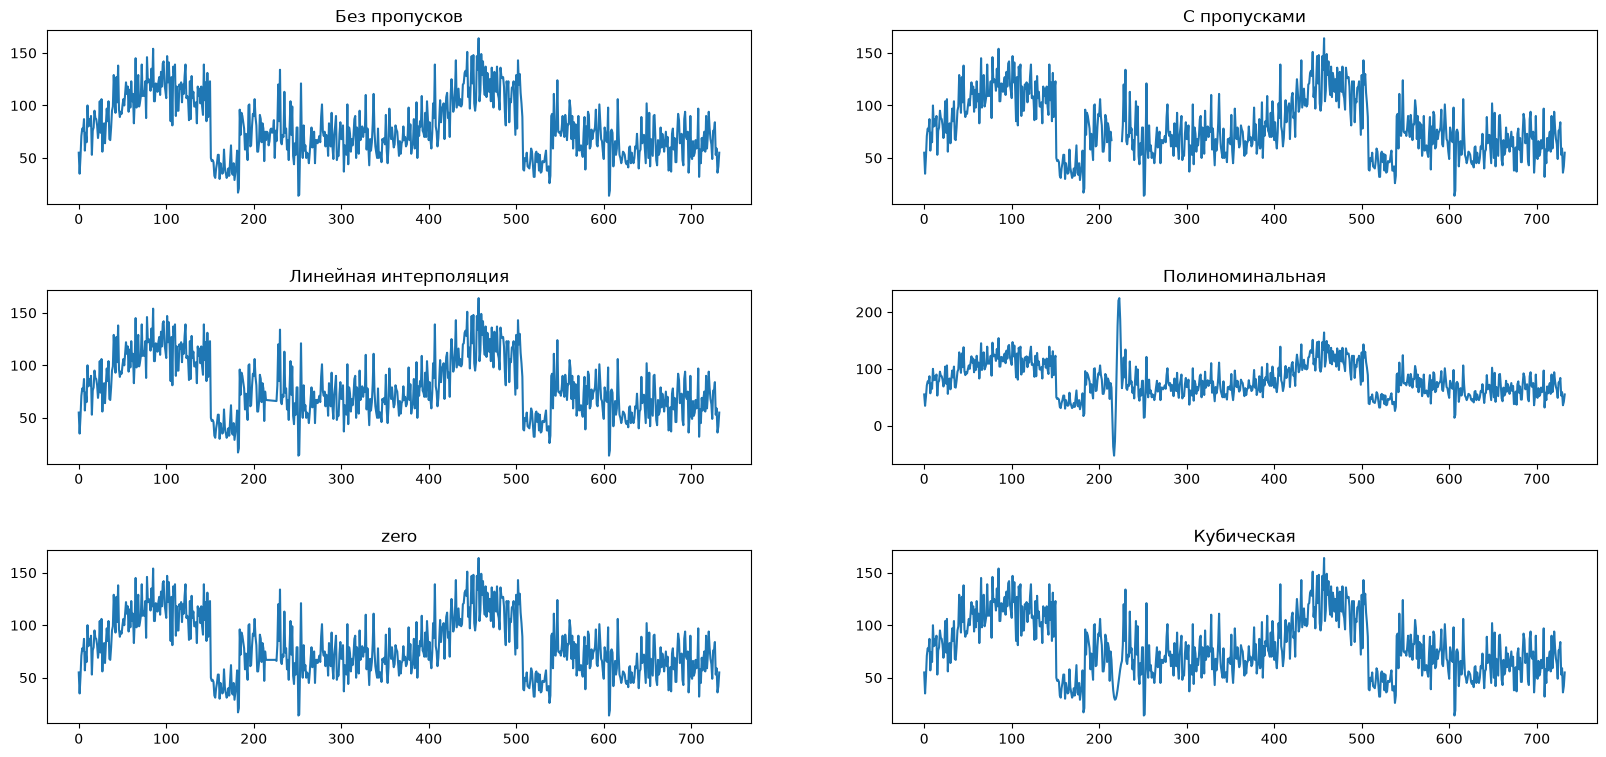

In [28]:

o_df.loc[215:225, 'chai_cups_sold'] = np.nan

lin_df = o_df.copy()
lin_df['chai_cups_sold'] = o_df['chai_cups_sold'].interpolate(method="linear")

cub_df = o_df.copy()
cub_df['chai_cups_sold'] = o_df['chai_cups_sold'].interpolate(method="cubic")

pol_df = o_df.copy()
pol_df['chai_cups_sold'] = o_df['chai_cups_sold'].interpolate(method="polynomial", order=5)

zero_df = o_df.copy()
zero_df['chai_cups_sold'] = o_df['chai_cups_sold'].interpolate(method="zero")


fig = plt.figure(figsize=(20, 9))
layout = (3, 2)
plt.subplots_adjust(wspace=0.2, hspace=0.5)

original_ax = plt.subplot2grid(layout, (0, 0))
lin_ax = plt.subplot2grid(layout, (1, 0))
cub_ax = plt.subplot2grid(layout, (2, 1))

pol_ax = plt.subplot2grid(layout, (1, 1))
zero_ax = plt.subplot2grid(layout, (2, 0))
 
df['chai_cups_sold'].plot(title="Без пропусков", ax = original_ax)  
o_df['chai_cups_sold'].plot(title="С пропусками", ax = plt.subplot2grid(layout, (0, 1)))  
lin_df['chai_cups_sold'].plot(title="Линейная интерполяция", ax = lin_ax) 
cub_df['chai_cups_sold'].plot(title="Кубическая", ax = cub_ax) 
pol_df['chai_cups_sold'].plot(title="Полиноминальная", ax = pol_ax) 
zero_df['chai_cups_sold'].plot(title="zero", ax=zero_ax)


### Работа с выбросами

In [29]:
import seaborn as sns

<Axes: >

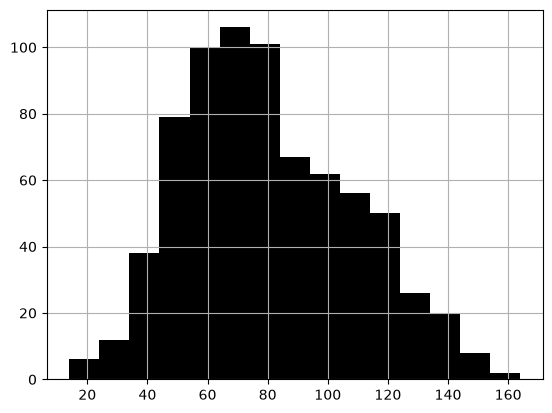

In [30]:
pdf = df.copy()
pdf['chai_cups_sold'].hist(bins=15, color="black")

Text(0.5, 1.0, 'Проданых чашек чая')

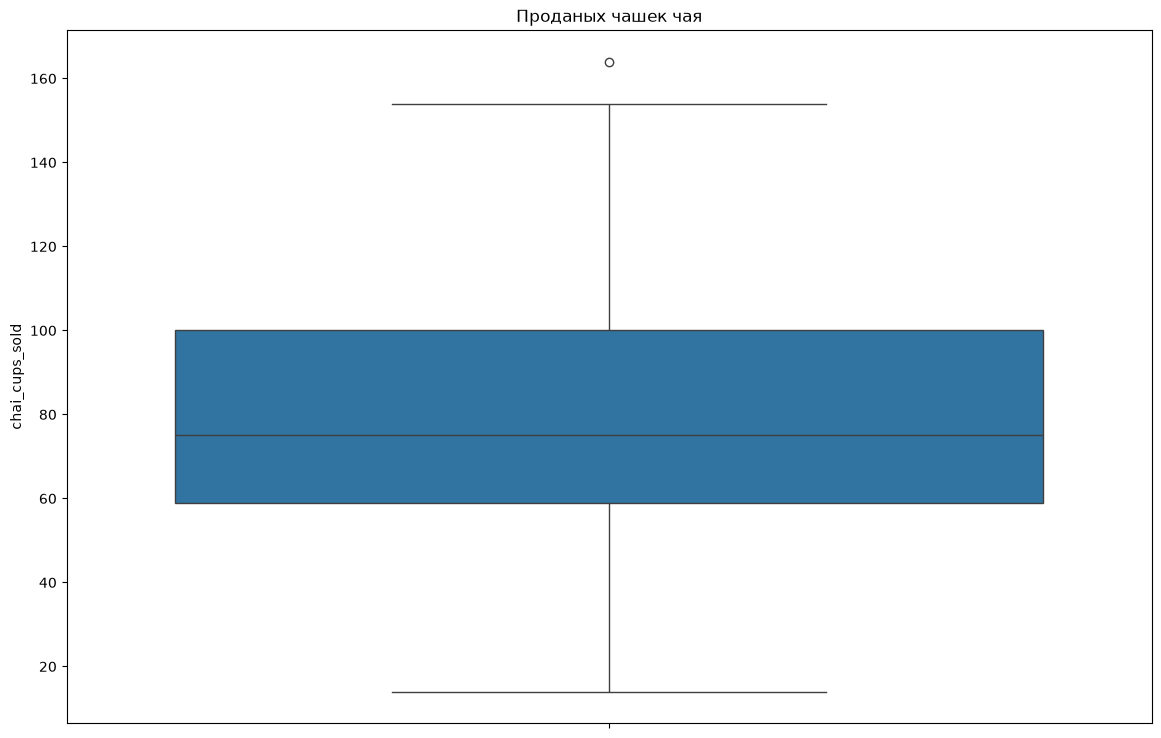

In [31]:
fig = plt.figure(figsize=(14, 9))
 
sns.boxplot(pdf['chai_cups_sold']).set_title('Проданых чашек чая')

Давайте напишем функцию для автоматического обнаружения выбросов во временном ряду с использованием алгоритма кластеризации из библиотеки scikit-learn: машина векторов поддержки одного класса, она изучает границы распределения (называемые « support ») и, следовательно, может классифицировать любые точки, лежащие за пределами границы, как выбросы.

In [32]:
from sklearn import preprocessing, svm

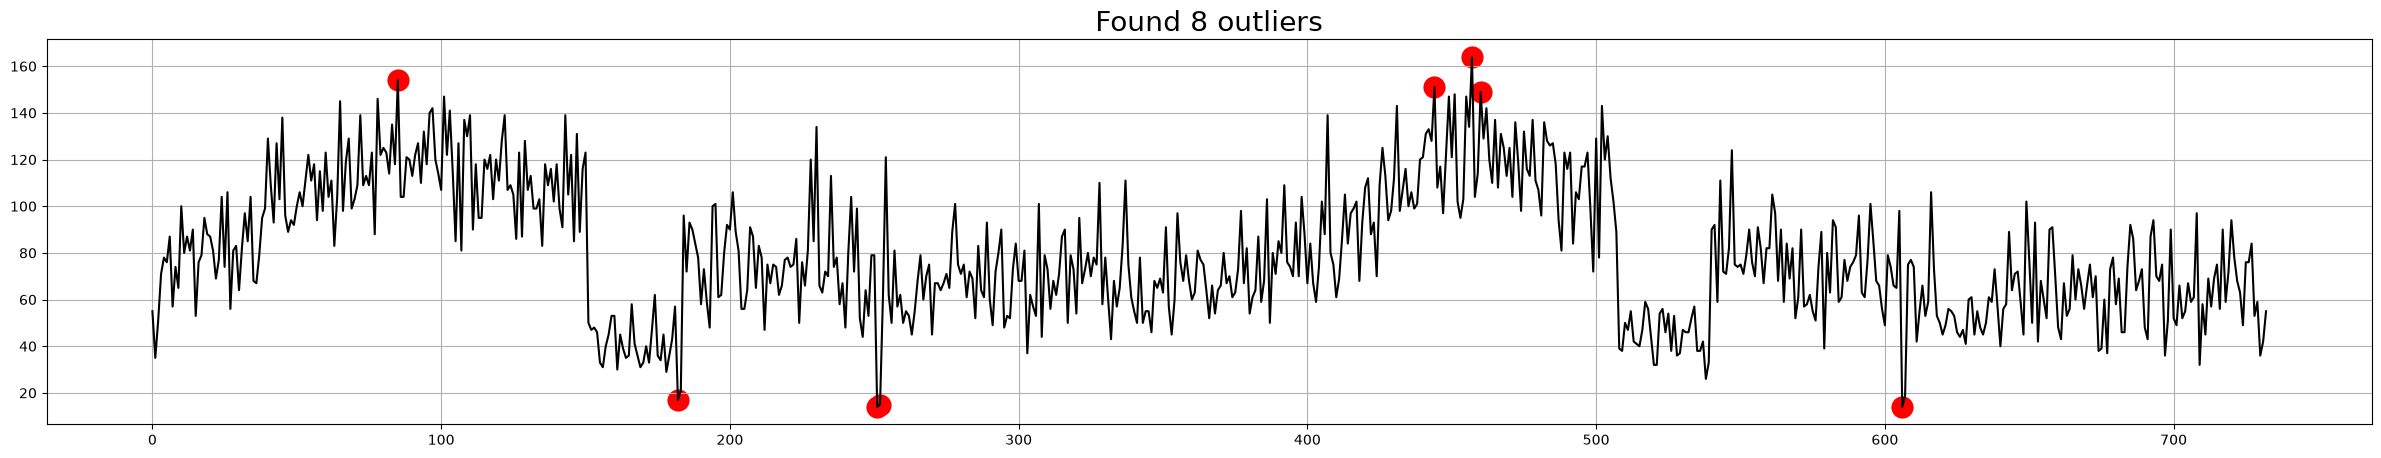

In [33]:
scaler = preprocessing.StandardScaler()
perc = 0.01

local_df = pdf['chai_cups_sold']

ts_scaled = scaler.fit_transform(local_df.values.reshape(-1,1))
model = svm.OneClassSVM(nu=perc, kernel="rbf", gamma=0.01)
model.fit(ts_scaled)
## dtf output
dtf_outliers =local_df.to_frame(name="ts")
dtf_outliers["index"] = range(len(local_df))
dtf_outliers["outlier"] = model.predict(ts_scaled)
dtf_outliers["outlier"] = dtf_outliers["outlier"].apply(lambda
                                                            x: 1 if x==-1 else 0)
## plot
fig, ax = plt.subplots(figsize=(30, 5))
ax.plot(dtf_outliers["index"], dtf_outliers["ts"],
        color="black")
ax.scatter(x=dtf_outliers[dtf_outliers["outlier"]==1]["index"],
           y=dtf_outliers[dtf_outliers["outlier"]==1]['ts'],
           color='red', linewidths=10)
plt.title(f"Found {sum(dtf_outliers['outlier']==1)} outliers", fontdict={'fontsize': 20})
ax.grid(True)
plt.show()

Но что нам делать с выбросами после обнаружения? Здесь нет оптимальной стратегии: прогнозировать временные ряды проще без точек данных, которые значительно отличаются от других наблюдений, но удаление этих точек может глубоко изменить распределение данных. Если вы решили исключить выбросы, наиболее удобный способ их удаления - интерполяция.

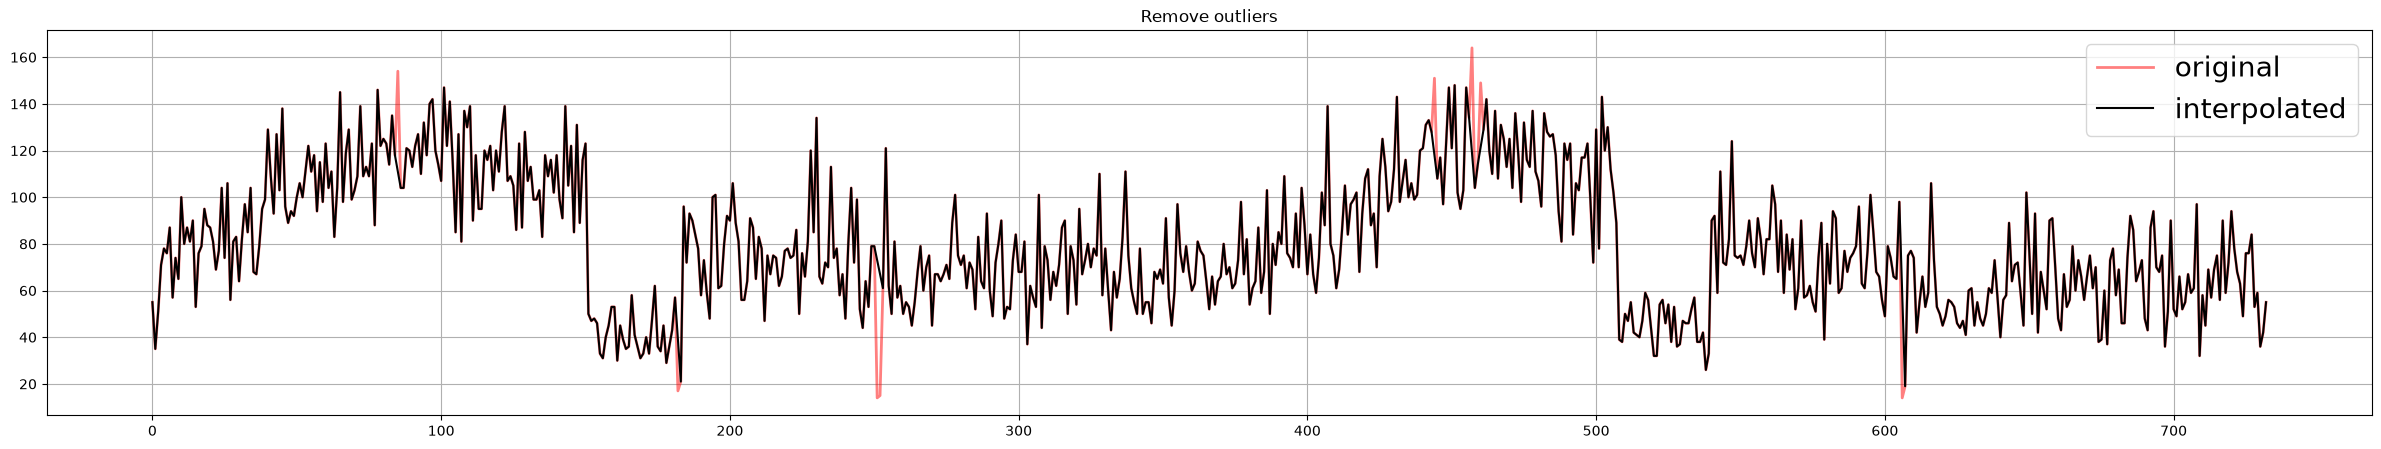

In [34]:
outliers_idx = dtf_outliers[dtf_outliers["outlier"]==1].index

ts_clean = local_df.copy()
ts_clean.loc[outliers_idx] = np.nan
ts_clean = ts_clean.interpolate(method="linear")
ax = local_df.plot(figsize=(30, 5), color="red", alpha=0.5,
             title="Remove outliers", label="original", legend=True, linewidth=2)
ts_clean.plot(ax=ax, grid=True, color="black",
              label="interpolated", legend=True)
plt.legend(fontsize="20")
plt.show()